## Replication of figure3

**Paper:** Evaluating Stochastic Seeding Strategies in Networks (Chin et al., 2022, Management Science)

**Data:** Cai et al. (2015) village network

**Figure 3:** Compares difference-in-means, Horvitz-Thompson, and Hájek estimators by RMSE and 90% confidence-interval coverage

In [53]:
from pathlib import Path
import itertools
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import norm
from time import perf_counter

### 1. Data

In [ ]:
data_path = Path("../data/0422allinforawnet.dta")
reps = 5000
seed = 6165
alphas = (-3, -2, -1, 0)
betas = (0, 2, 4, 6, 8, 10)

In [55]:
colors = {"dm": "#E69F00", "hajek": "#009E73", "ht": "#56B4E9"}
labels = {"dm": "difference-in-means", "hajek": "Hajek", "ht": "Horvitz-Thompson"}
markers = {"dm": "s", "hajek": "^", "ht": "o"}

### 2. Network preprocessing and one-hop seed probabilities

Reference: Chin et al. (2022) github
1. `main_simulations.R`: https://github.com/deaneckles/eval_stochastic_seeding/blob/main/simulations/main_simulations.R
2. `village.R`: https://github.com/deaneckles/eval_stochastic_seeding/blob/main/simulations/village.R

In [ ]:
# Network preprocessing and seed-selection probabilities

def load_villages(path):
    df = pd.read_stata(path, convert_categoricals=False)
    df['address'] = df['address'].astype('string')
    df['network_address'] = df['network_address'].astype('string')

    addresses = pd.unique(df['address'].dropna())
    villages = []
    for address in addresses:

        # Skip if address is empty
        if address == '':
            continue

        # Keep valid within-village edges
        sub = df.loc[(df['address'] == address) & 
                     (df['network_address'] == address) &
                     df['network_id'].notna() &
                     (df['id'] != 99) &
                     (df['network_id'] != 99),
                     ['id', 'network_id']]

        # Filter num edge <= 25
        if len(sub) <= 25:
            continue

        # Create a directed network
        graph = nx.DiGraph()
        graph.add_edges_from(sub.itertuples(index=False, name=None))

        nodes = list(graph.nodes())
        n = len(nodes)

        # Skip if num nodes < 2 (need to select at least 2 seeds)
        if n < 2:
            continue

        # Create adjacency matrix
        adjacency = nx.to_numpy_array(graph, nodelist=nodes, dtype=float)

        # One-hop nomination probabilities
        row_degrees = adjacency.sum(axis=1)   # out-degree
        valid = row_degrees > 0
        q = (adjacency[valid] / row_degrees[valid, None]).sum(axis=0) / valid.sum()

        # All possible pairs of two seeds
        pairs = np.array(list(itertools.combinations(range(n), 2)), dtype=np.int32)

        # Random targeting seed set probabilities
        p_rand = np.full(len(pairs), 1.0 / len(pairs))
        # One-hop targeting seed set probabilities
        weights = q[pairs[:, 0]] * q[pairs[:, 1]]
        p_nom = weights / weights.sum()

        # Row-normalized adjacency matrix for adoption diffusion
        norm_adj = np.divide(adjacency,
                             row_degrees[:, None],
                             out=np.zeros_like(adjacency),
                             where=row_degrees[:, None] > 0)

        villages.append({'n': n,
                         'pairs': pairs,
                         'p_rand': p_rand,
                         'p_nom': p_nom,
                         'norm_adj': norm_adj})

    return villages

### 3. Adoption diffusion

Reference: Chin et al. (2022) github
1. `outcomes.R`: https://github.com/deaneckles/eval_stochastic_seeding/blob/main/simulations/outcomes.R

In [ ]:
# Adoption diffusion (linear-in-means model)
# Author's lim_endogenous() (b_degree = 0, n_steps = 3)

def outcome(v, seeds, intercept, spillover, rng):

    # Initialize selected seeds as adopters
    y = np.zeros(v['n'], dtype=bool)   # v['n']: total nodes num in villiage i
    y[seeds] = True

    # Simulate three diffusion time steps
    for _ in range(3):
        avg_neighbors = v['norm_adj'] @ y.astype(float)
        latent = (intercept + spillover * avg_neighbors + rng.standard_normal(v['n']))   # adoption model
        # Update adoption status
        y |= latent > 0   # adoption is irreversible

    return float(y.mean())

### 4. Estimators and variance estimates

Reference: Chin et al. (2022) github
1. `estimators.R`: https://github.com/deaneckles/eval_stochastic_seeding/blob/main/simulations/estimators.R

In [ ]:
# Treatment-effect estimators and variance estimates

def estimate(y, w, pr, pn, rho=0.5):
    n = len(y)

    # Seed-selection weights
    design = rho * pn + (1 - rho) * pr
    weight_a = pn / design
    weight_b = pr / design

    # Difference-in-means estimator
    y_a = y[w == 1]
    y_b = y[w == 0]
    dm = (y_a.mean() - y_b.mean()) if len(y_a) > 0 and len(y_b) > 0 else np.nan

    # Horvitz-Thompson estimator
    score = (weight_a - weight_b) * y
    ht = np.mean(score)

    # Hajek estimator
    mu_a = np.sum(weight_a * y) / np.sum(weight_a)
    mu_b = np.sum(weight_b * y) / np.sum(weight_b)
    hajek = mu_a - mu_b

    # Variance estimates
    dmvar = (np.var(y_a, ddof=1) / len(y_a) + np.var(y_b, ddof=1) / len(y_b)) if len(y_a) > 1 and len(y_b) > 1 else np.nan
    htvar = np.mean((score - ht) ** 2) / n
    hscore = mu_a * weight_a - mu_b * weight_b - score
    hvar = np.mean(hscore ** 2) / n

    return {'dm': dm,
            'ht': ht,
            'hajek': hajek,
            'dm_var_est': dmvar,
            'ht_var_est': htvar,
            'hajek_var_est': hvar}

### 5. One Monte Carlo replication

Reference: Chin et al. (2022) github
1. `runner.R`: https://github.com/deaneckles/eval_stochastic_seeding/blob/main/simulations/runner.R

In [ ]:
# One Monte Carlo replication
# draw_experiment_data() and run_experiment()

def one_rep(villages, n_villages, intercept, spillover, rng):
    
    # Sample villages without replacement
    indices = rng.choice(len(villages), size=n_villages, replace=False)
    
    y = np.zeros(n_villages)
    yn = np.zeros(n_villages)
    yr = np.zeros(n_villages)
    pr = np.zeros(n_villages)
    pn = np.zeros(n_villages)

    # Assign each village to one-hop or random targeting
    w = rng.binomial(1, 0.5, size=n_villages)

    for j, idx in enumerate(indices):
        v = villages[idx]

        # Select seed pairs under both strategies
        nom_idx = rng.choice(len(v['pairs']), p=v['p_nom'])
        rand_idx = rng.choice(len(v['pairs']), p=v['p_rand'])

        chosen_idx = nom_idx if w[j] else rand_idx

        # Probabilities of the observed seed pair
        pr[j] = v['p_rand'][chosen_idx]
        pn[j] = v['p_nom'][chosen_idx]

        # Simulate adoption outcomes under both strategies
        yn[j] = outcome(v, v['pairs'][nom_idx], intercept, spillover, rng)
        yr[j] = outcome(v, v['pairs'][rand_idx], intercept, spillover, rng)

        # Observed outcome under the assigned strategy
        y[j] = yn[j] if w[j] else yr[j]

    # Estimate treatment effects and variances
    result = estimate(y, w, pr, pn)

    result.update({'tau': float((yn - yr).mean()),
                   'n_villages': n_villages,
                   'intercept': intercept,
                   'b_spill': spillover})

    return result

### 6. RMSE and confidence-interval coverage

Reference: Chin et al. (2022) github
1. `lim_analyze.R`: https://github.com/deaneckles/eval_stochastic_seeding/blob/main/simulations/lim_analyze.R
2. `analyze.R`: https://github.com/deaneckles/eval_stochastic_seeding/blob/main/simulations/analyze.R

In [ ]:
# Summarize RMSE and 90% confidence interval coverage

def summarize(raw):
    results = []
    z = norm.ppf(0.95)

    for (N, a, b), g in raw.groupby(['n_villages', 'intercept', 'b_spill'], sort=True):
        tau = g['tau'].to_numpy()
        true_tau = tau.mean()

        for est in ['dm', 'ht', 'hajek']:
            e = g[est].to_numpy()
            vv = g[f'{est}_var_est'].to_numpy()
            rmse = np.sqrt(np.nanmean((e - tau) ** 2))   # RMSE
            cover = np.where(vv == 0, e == true_tau, np.abs(e - true_tau) <= z * np.sqrt(vv))   # 90% confidence interval coverage
            cover = np.where(np.isfinite(e) & np.isfinite(vv), cover, np.nan)

            results.append({'n_villages': N,
                            'intercept': a,
                            'b_spill': b,
                            'estimator': est,
                            'rmse': rmse,
                            'coverage': np.nanmean(cover)})

    return pd.DataFrame(results)

### 7. Figure 3 plot

In [ ]:
def plot_figure3(summary, reps):
    labels = {"dm": "Difference-in-Means", "hajek": "Hájek", "ht": "Horvitz-Thompson"}
    alpha_vals=[-3,-2,-1,0]
    nvals=[50,150]
    fig,axes=plt.subplots(2,8,figsize=(17,7.5),sharex=True,layout='constrained')
    for ri,N in enumerate(nvals):
        for ci,a in enumerate(alpha_vals):
            for side in (0,1):
                ax=axes[ri,ci+side*4]
                d=summary[(summary.n_villages==N)&(summary.intercept==a)]
                for key in ('dm','ht','hajek'):
                    q=d[d.estimator==key].sort_values('b_spill')
                    ax.plot(q.b_spill,q.rmse if side==0 else q.coverage,
                            color=colors[key],marker=markers[key],markersize=3,linewidth=1,
                            label=labels[key])
                ax.set_xticks([0,2,4,6,8,10]); ax.grid(alpha=.18)
                if ri==0: ax.set_title(rf'$\alpha={a}$',fontsize=11)
                if ri==1: ax.set_xlabel(r'spillover effect $\beta$',fontsize=9)
                if ci==0: ax.set_ylabel(f'RMSE\nN={N}')
                if ci==0 and side==1: ax.set_ylabel(f'coverage rate\nN={N}')
                if side==0:
                    ax.set_ylim(0, .08)
                else:
                    ax.axhline(.90,color='gray',linestyle='--',linewidth=1)
                    band_bottom=.90-1.96*np.sqrt(.9*.1/reps)
                    ax.axhspan(band_bottom,1,color='gray',alpha=.10)
                    ax.set_ylim(.84, .925)
    handles,labels=axes[0,0].get_legend_handles_labels()
    fig.legend(handles,labels,ncol=3,loc='outside lower center',bbox_to_anchor=(.5,-.045),frameon=False)
    fig.suptitle('Figure 3 replication — RMSE (left) and 90% CI coverage (right)',fontsize=13)
    plt.show()

### 8. Cai et al. network data  

In [62]:
# Load village networks
villages = load_villages(data_path)
print(f"Number of villages: {len(villages)}")

Number of villages: 150


### 9. Run Monte Carlo simulations

In [63]:
rng = np.random.default_rng(seed)
results = []

total = 2 * len(alphas) * len(betas) * reps
completed = 0

for N in (50, len(villages)):
    for alpha in alphas:
        for beta in betas:
            for rep in range(reps):
                result = one_rep(villages, N, alpha, beta, rng)
                result["rep"] = rep + 1
                results.append(result)

            completed += reps
            print(f"N={N}, alpha={alpha}, beta={beta} | "
                  f"Progress: {completed / total:.1%}",
                  flush=True)

raw = pd.DataFrame(results)
raw.to_csv("figure3_raw.csv", index=False)

print(f"Simulation rows: {len(raw):,}")
display(raw.head())

N=50, alpha=-3, beta=0 | Progress: 2.1%
N=50, alpha=-3, beta=2 | Progress: 4.2%
N=50, alpha=-3, beta=4 | Progress: 6.2%
N=50, alpha=-3, beta=6 | Progress: 8.3%
N=50, alpha=-3, beta=8 | Progress: 10.4%
N=50, alpha=-3, beta=10 | Progress: 12.5%
N=50, alpha=-2, beta=0 | Progress: 14.6%
N=50, alpha=-2, beta=2 | Progress: 16.7%
N=50, alpha=-2, beta=4 | Progress: 18.8%
N=50, alpha=-2, beta=6 | Progress: 20.8%
N=50, alpha=-2, beta=8 | Progress: 22.9%
N=50, alpha=-2, beta=10 | Progress: 25.0%
N=50, alpha=-1, beta=0 | Progress: 27.1%
N=50, alpha=-1, beta=2 | Progress: 29.2%
N=50, alpha=-1, beta=4 | Progress: 31.2%
N=50, alpha=-1, beta=6 | Progress: 33.3%
N=50, alpha=-1, beta=8 | Progress: 35.4%
N=50, alpha=-1, beta=10 | Progress: 37.5%
N=50, alpha=0, beta=0 | Progress: 39.6%
N=50, alpha=0, beta=2 | Progress: 41.7%
N=50, alpha=0, beta=4 | Progress: 43.8%
N=50, alpha=0, beta=6 | Progress: 45.8%
N=50, alpha=0, beta=8 | Progress: 47.9%
N=50, alpha=0, beta=10 | Progress: 50.0%
N=150, alpha=-3, beta=

,dm,ht,hajek,dm_var_est,ht_var_est,hajek_var_est,tau,n_villages,intercept,b_spill,rep
0,0.010419,0.009922,0.003016,0.000020,0.000037,0.000003,0.003991,50,-3,0,1
1,0.001835,0.008527,0.002872,0.000038,0.000053,0.000007,0.001458,50,-3,0,2
2,-0.000456,0.003098,0.000524,0.000050,0.000038,0.000005,-0.001904,50,-3,0,3
3,0.005876,-0.005194,-0.003205,0.000051,0.000076,0.000010,-0.000253,50,-3,0,4
4,-0.006305,-0.000569,-0.003658,0.000027,0.000055,0.000005,0.002132,50,-3,0,5


### 10. Summarize

In [ ]:
summary = summarize(raw)
display(summary.head(12))

,n_villages,intercept,b_spill,estimator,rmse,coverage,tau,mean_estimate
0,50,-3,0,dm,0.006470,0.8950,0.000027,-0.000064
1,50,-3,0,ht,0.008561,0.8966,0.000027,-0.000092
2,50,-3,0,hajek,0.003540,0.8894,0.000027,-0.000065
3,50,-3,2,dm,0.007212,0.8974,0.001739,0.001634
4,50,-3,2,ht,0.009497,0.8838,0.001739,0.001544
5,50,-3,2,hajek,0.004351,0.8906,0.001739,0.001646
6,50,-3,4,dm,0.010747,0.8956,0.009703,0.009754
7,50,-3,4,ht,0.012807,0.8856,0.009703,0.009533
8,50,-3,4,hajek,0.007538,0.8666,0.009703,0.009511
9,50,-3,6,dm,0.020753,0.8874,0.030799,0.031406


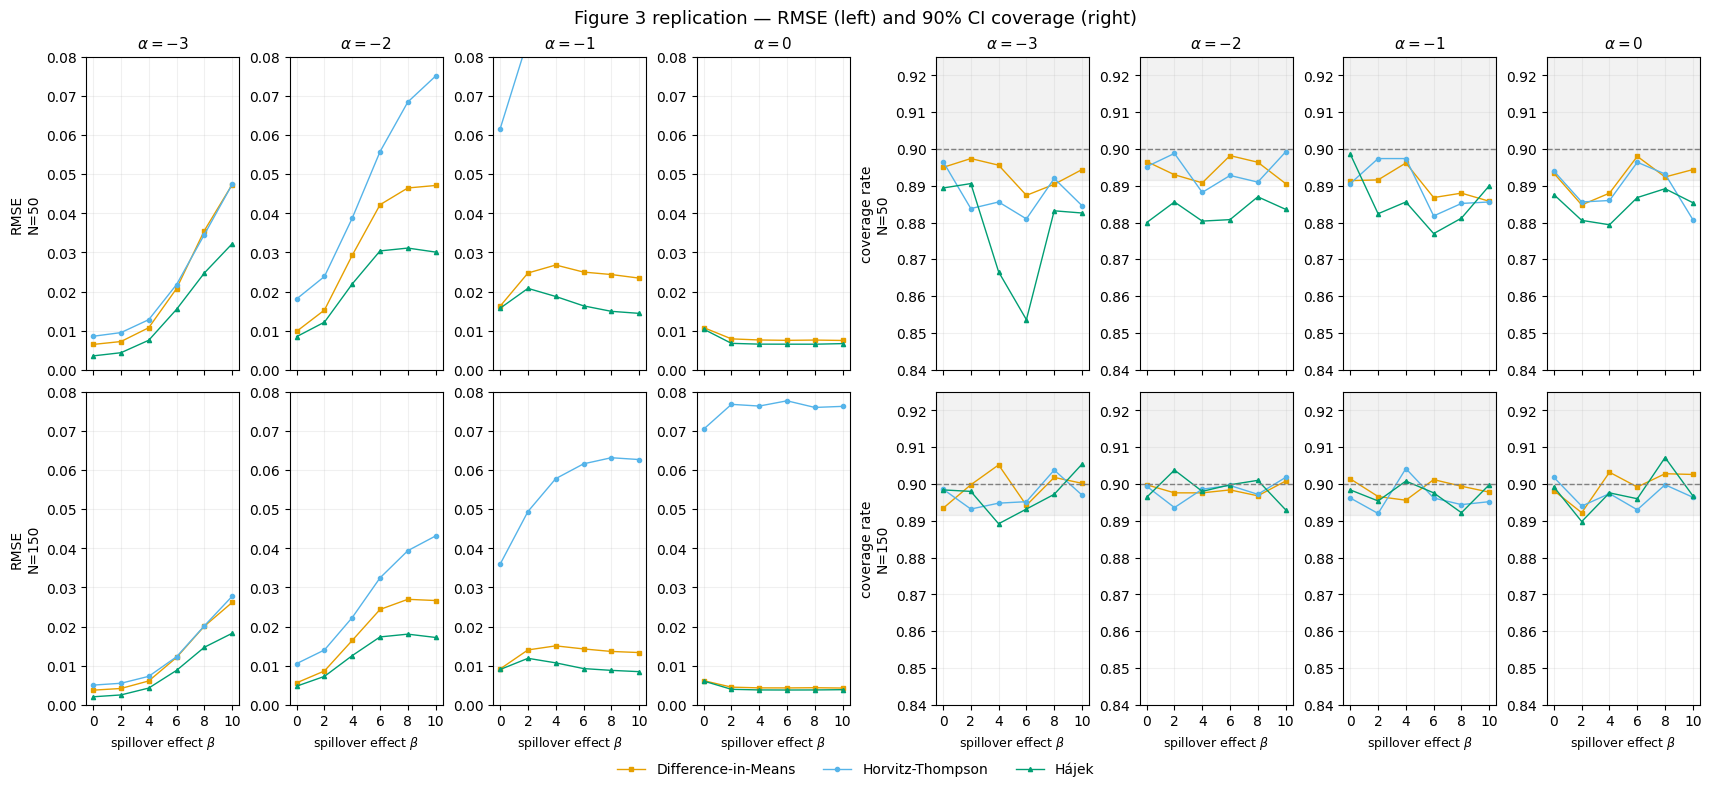

In [88]:
plot_figure3(summary, reps)